## Scénario 4 : Your Station, Please!

La fonction analyser_gare(nom) affiche les chiffres d'une gare choisie : les années disponibles, la fréquentation de la dernière année, l'évolution depuis la première année et les remarques des CFF, avec un graphique de 2018 à 2025. Il suffit d'écrire par exemple analyser_gare("Genève"). Le nom doit être écrit exactement comme dans le fichier, avec les accents, sinon la fonction affiche un message. Attention, on compte des montées et des descentes, pas des voyageurs, et la valeur 49 veut dire moins de 50.

In [9]:
# on charge pandas (pd) pour les tableaux et matplotlib (plt) pour les graphiques
import pandas as pd
import matplotlib.pyplot as plt
# on lit le fichier passagierfrequenz.csv (ses colonnes sont séparées par des ;)
df = pd.read_csv("data/passagierfrequenz.csv", sep=";")

In [10]:
def analyser_gare(nom):
    # on enlève les espaces au début et à la fin du nom tapé
    nom = nom.strip()
    # si on n'a rien tapé, on s'arrête tout de suite
    if nom == "":
        print("Écris un nom de gare.")
        return

    # 1. on garde les lignes de la gare demandée, triées par année
    gare = df[df["Bahnhof_Gare_Stazione"] == nom]
    gare = gare.sort_values("Jahr_Annee_Anno")
    annees = gare["Jahr_Annee_Anno"].tolist()
    valeurs = gare["DTV_TJM_TGM"].tolist()

    # si la liste est vide, le nom n'existe pas : on propose des gares proches et on s'arrête
    if len(annees) == 0:
        print(f"Gare introuvable : {nom}")
        noms = df["Bahnhof_Gare_Stazione"]
        proches = noms[noms.str.contains(nom, case=False, regex=False)].unique().tolist()
        if len(proches) > 0:
            print("Tu voulais peut-être dire :", proches)
        else:
            print("Vérifie l'orthographe exacte, avec les accents (par exemple Zürich HB ou Genève).")
        return

    # 2. on affiche les chiffres
    print("Gare :", nom)
    print("Années disponibles :", annees)
    print(f"En {annees[-1]} : {int(valeurs[-1])} montées et descentes par jour")
    # l'évolution n'a de sens que s'il y a au moins deux années
    if len(annees) > 1:
        evolution = (valeurs[-1] - valeurs[0]) / valeurs[0] * 100
        print(f"Évolution depuis {annees[0]} : {evolution:.1f} %")

    # les remarques des CFF sur cette gare (changements de comptage, trains de l'étranger...)
    remarques = gare["Remarques"].dropna().unique().tolist()
    if len(remarques) > 0:
        print("Remarques des CFF :", remarques)

    # 3. on dessine le graphique, avec toujours les années 2018 à 2025
    plt.bar(annees, valeurs)
    plt.xticks(range(2018, 2026))
    plt.title(f"{nom}: boardings + alightings per day")
    plt.xlabel("Year")
    plt.ylabel("Boardings + alightings per day")
    plt.figtext(0.5, -0.02, "source: SBB open data (PF)", ha="center", fontsize=9)
    plt.show()

Gare : Genève
Années disponibles : [2018, 2022, 2023, 2024, 2025]
En 2025 : 83100 montées et descentes par jour
Évolution depuis 2018 : 37.4 %
Remarques des CFF : ['Les personnes montant et descendant des trains en provenance ou à destination de l’étranger ne sont que partiellement recensées.']


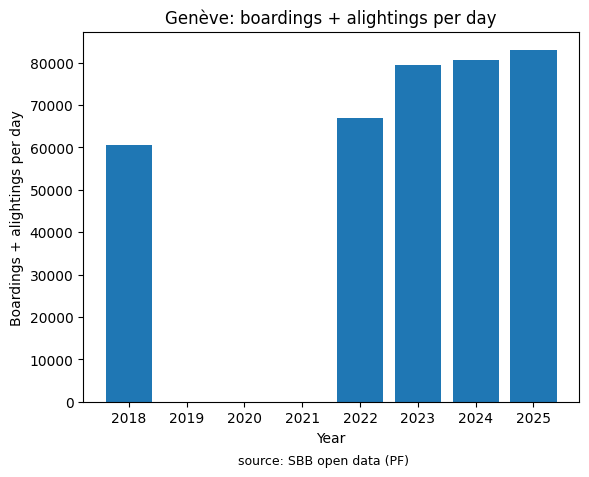

In [11]:
analyser_gare("Genève")

Gare : Lausanne
Années disponibles : [2018, 2022, 2023, 2024, 2025]
En 2025 : 97500 montées et descentes par jour
Évolution depuis 2018 : 9.3 %
Remarques des CFF : ['Les personnes montant et descendant des trains en provenance ou à destination de l’étranger ne sont que partiellement recensées.']


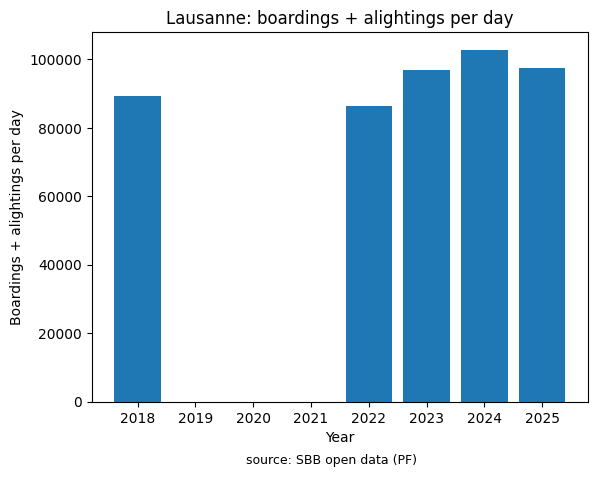

In [12]:
analyser_gare("Lausanne")

Gare : Lancy-Bachet
Années disponibles : [2022, 2023, 2024, 2025]
En 2025 : 9300 montées et descentes par jour
Évolution depuis 2022 : 75.5 %


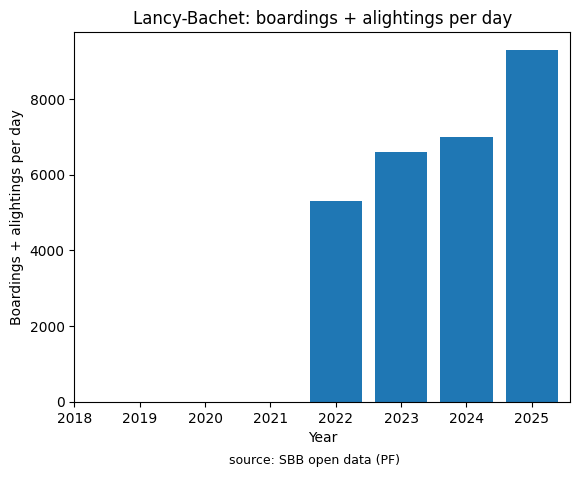

In [13]:
analyser_gare("Lancy-Bachet")

In [14]:
analyser_gare("Zurich HBB")

Gare introuvable : Zurich HBB
Vérifie l'orthographe exacte, avec les accents (par exemple Zürich HB ou Genève).


Gare : Zürich HB
Années disponibles : [2018, 2022, 2023, 2024, 2025]
En 2025 : 449800 montées et descentes par jour
Évolution depuis 2018 : 6.2 %
Remarques des CFF : ['Y compris ZLOE, ZMUS et ZUSZ.', 'Y compris ZLOE et ZMUS; sans SZU.']


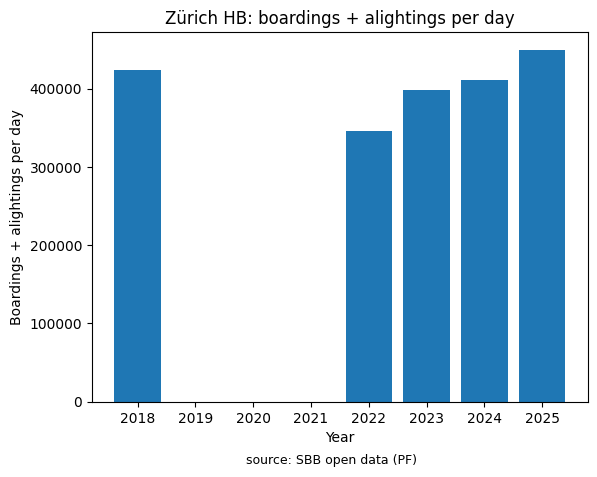

In [15]:
analyser_gare("Zürich HB")

### Antisèche : noms exacts des gares pour la démo

Le nom doit être écrit exactement comme dans le fichier des CFF. Si on se trompe, la fonction propose les gares qui contiennent le mot tapé.

| On pense à… | On écrit |
|---|---|
| Zurich, gare centrale | Zürich HB |
| Aéroport de Zurich | Zürich Flughafen |
| Genève Cornavin | Genève |
| Aéroport de Genève | Genève-Aéroport |
| Bâle | Basel SBB |
| Berne | Bern |
| Lucerne | Luzern |
| Fribourg | Fribourg/Freiburg |
| Bienne | Biel/Bienne |
| Sierre | Sierre/Siders |
| Renens | Renens VD |
| Saint-Gall | St. Gallen |
| Saint-Moritz | St. Moritz |
| Coire | Chur |
| Interlaken | Interlaken Ost |
| Yverdon | Yverdon-les-Bains |

Noms simples, qui marchent tels quels : Lausanne, Winterthur, Olten, Zug, Thun, Aarau, Baden, Nyon, Morges, Vevey, Montreux, Neuchâtel, Sion, Martigny, Delémont, Lugano, Bellinzona, Locarno, Brig, Visp, Zermatt, Lancy-Pont-Rouge, Lancy-Bachet.

In [17]:
gare_nom = input("Veuillez écrire un nom d'une gare ? :")
analyser_gare(gare_nom)

Écris un nom de gare.
